In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [ ]:
data = pd.read_csv('/content/drive/MyDrive/ml_projects/Mall_Customers.csv')

In [ ]:
df = data
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0


In [ ]:
df.shape

(200, 5)

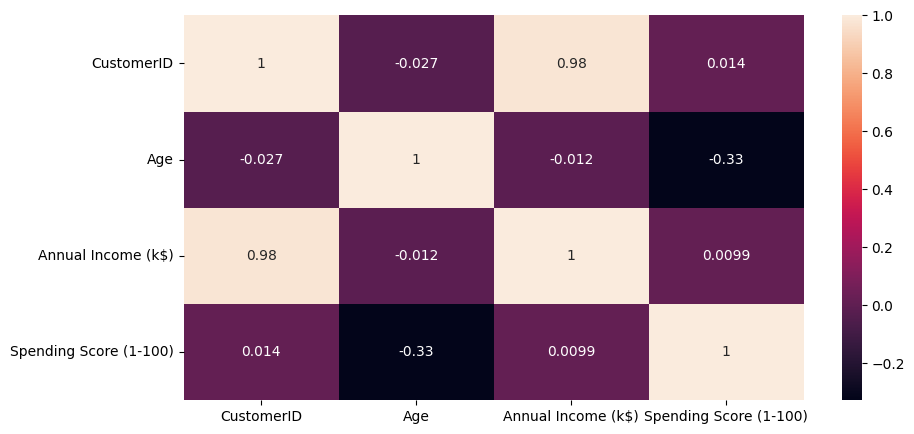

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

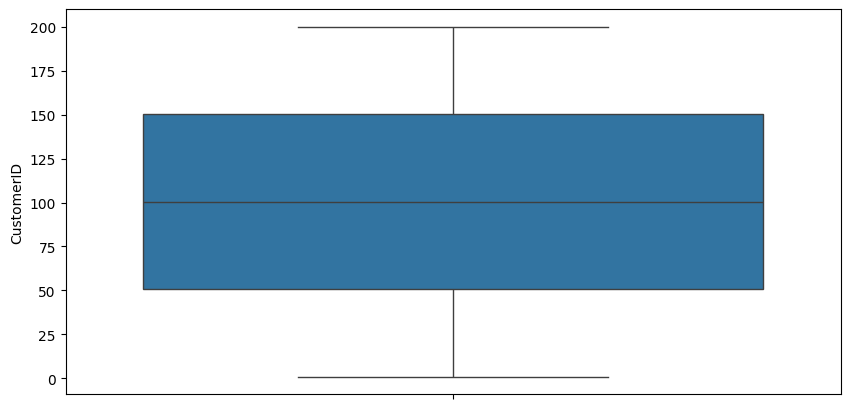

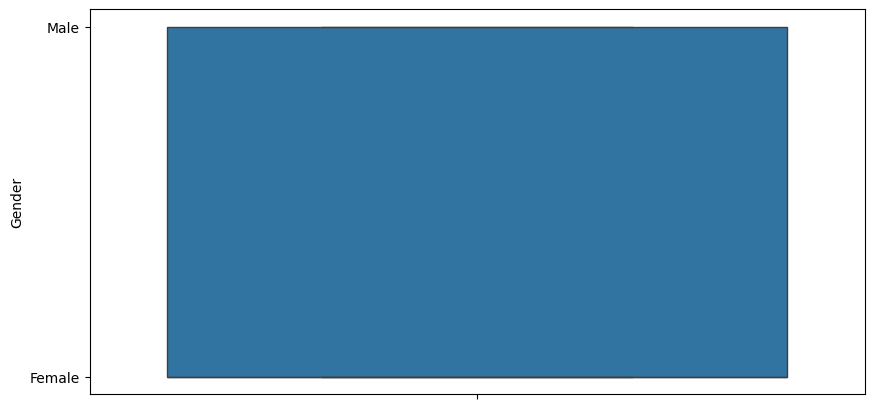

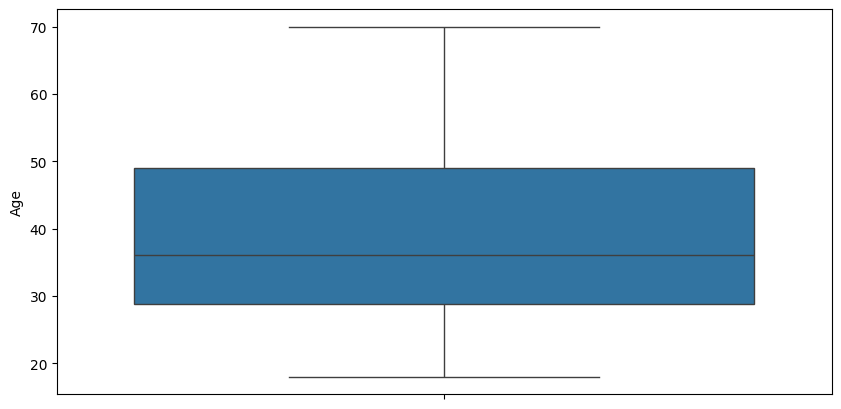

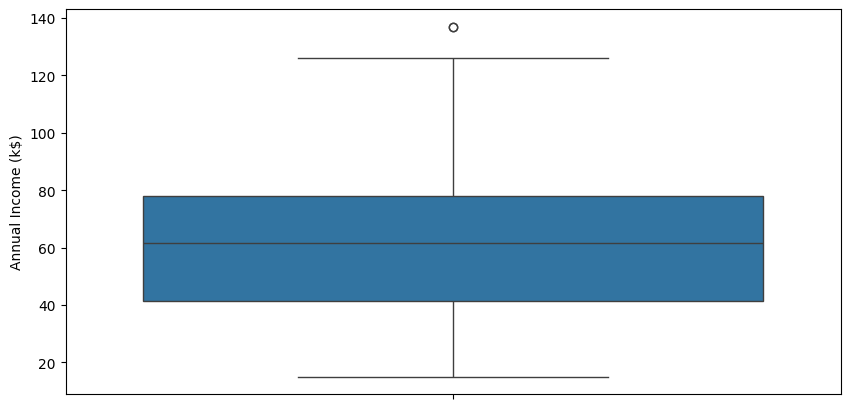

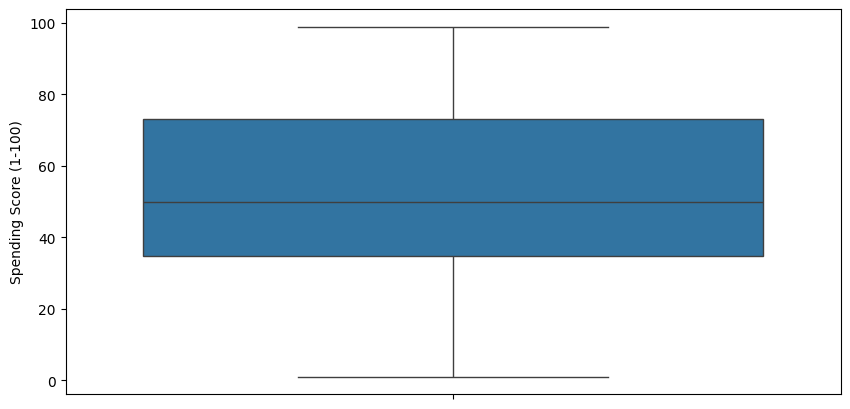

In [ ]:
col = df.columns
for i in col:
  plt.figure(figsize=(10,5))
  sns.boxplot(df[i])
  plt.show()

In [ ]:
encoder = OneHotEncoder(sparse_output=False,handle_unknown='ignore')
encoder_df = encoder.fit_transform(df[['Gender']])
encoded_df = pd.DataFrame(
    encoder_df,
    columns=encoder.get_feature_names_out(['Gender']),
    index=df.index
)
df = pd.concat(
    [df.drop('Gender', axis=1), encoded_df],
    axis=1
)

In [ ]:
df.head()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male
0,1,19,15,39,0.0,1.0
1,2,21,15,81,0.0,1.0
2,3,20,16,6,1.0,0.0
3,4,23,16,77,1.0,0.0
4,5,31,17,40,1.0,0.0


In [ ]:
std = StandardScaler()
# Use errors='ignore' to avoid KeyError if the cell is rerun
df.drop(['CustomerID'], axis=1, errors='ignore', inplace=True)

# Initialize df_scaled by copying the original DataFrame
df_scaled = df.copy()

# Fit and scale the specified columns
df_scaled[['Annual Income (k$)', 'Spending Score (1-100)']] = std.fit_transform(df[['Annual Income (k$)', 'Spending Score (1-100)']])
df_scaled

,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male
0,19,-1.738999,-0.434801,0.0,1.0
1,21,-1.738999,1.195704,0.0,1.0
2,20,-1.700830,-1.715913,1.0,0.0
3,23,-1.700830,1.040418,1.0,0.0
4,31,-1.662660,-0.395980,1.0,0.0
...,...,...,...,...,...
195,35,2.268791,1.118061,1.0,0.0
196,45,2.497807,-0.861839,1.0,0.0
197,32,2.497807,0.923953,0.0,1.0
198,32,2.917671,-1.250054,0.0,1.0


In [ ]:
df_scaled.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male
0,19,-1.738999,-0.434801,0.0,1.0
1,21,-1.738999,1.195704,0.0,1.0
2,20,-1.700830,-1.715913,1.0,0.0
3,23,-1.700830,1.040418,1.0,0.0
4,31,-1.662660,-0.395980,1.0,0.0


In [ ]:
df_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,200.0,3.885000e+01,13.969007,18.000000,28.750000,36.000000,49.000000,70.000000
Annual Income (k$),200.0,-2.131628e-16,1.002509,-1.738999,-0.727509,0.035879,0.665675,2.917671
Spending Score (1-100),200.0,-1.465494e-16,1.002509,-1.910021,-0.599793,-0.007764,0.885132,1.894492
Gender_Female,200.0,5.600000e-01,0.497633,0.000000,0.000000,1.000000,1.000000,1.000000
Gender_Male,200.0,4.400000e-01,0.497633,0.000000,0.000000,0.000000,1.000000,1.000000


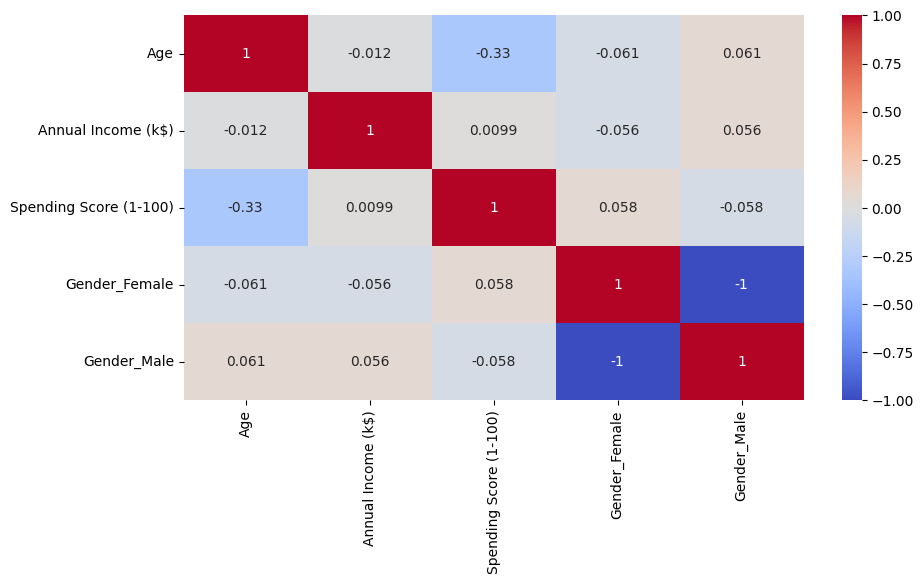

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(df_scaled.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

In [ ]:
x_scaled = df_scaled.drop(columns=['Gender_Female','Gender_Male','Age'], axis=1)
x_scaled.head()

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


In [ ]:
wcss = []
for k in range(1,11):
  km = KMeans(n_clusters=k, init = "k-means++", n_init = 10, random_state=42)
  km.fit(df_scaled)
  wcss.append(km.inertia_)

In [ ]:
wcss

[39330.06,
 11010.158689081261,
 6090.571048962726,
 2954.015688340553,
 2036.0553986747973,
 1449.1025289818297,
 1202.962445221625,
 1019.9235009390809,
 903.6677457331523,
 802.2899272842627]

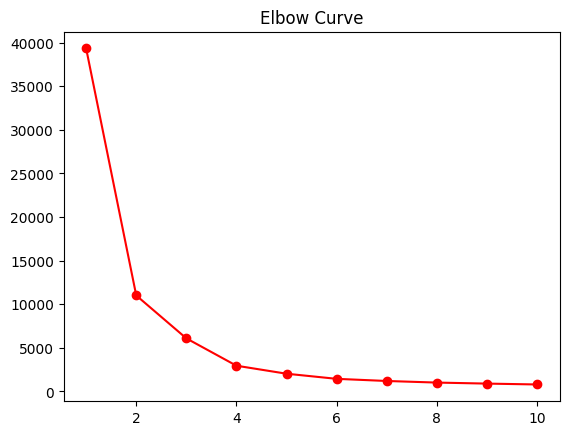

In [ ]:
plt.plot(range(1,11), wcss, marker = 'o',color = 'Red')
plt.title('Elbow Curve')
plt.show()

k = 5

In [ ]:
df.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male
0,19,15,39,0.0,1.0
1,21,15,81,0.0,1.0
2,20,16,6,1.0,0.0
3,23,16,77,1.0,0.0
4,31,17,40,1.0,0.0


In [ ]:
k = 5
km_final = KMeans(n_clusters=k, init = 'k-means++', n_init = 10, random_state=42)
df['cluster']=km_final.fit_predict(x_scaled)
df

,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male,cluster
0,19,15,39,0.0,1.0,4
1,21,15,81,0.0,1.0,2
2,20,16,6,1.0,0.0,4
3,23,16,77,1.0,0.0,2
4,31,17,40,1.0,0.0,4
...,...,...,...,...,...,...
195,35,120,79,1.0,0.0,1
196,45,126,28,1.0,0.0,3
197,32,126,74,0.0,1.0,1
198,32,137,18,0.0,1.0,3


In [ ]:
# x_scaled
# df = x_scaled

In [ ]:
# df.head()

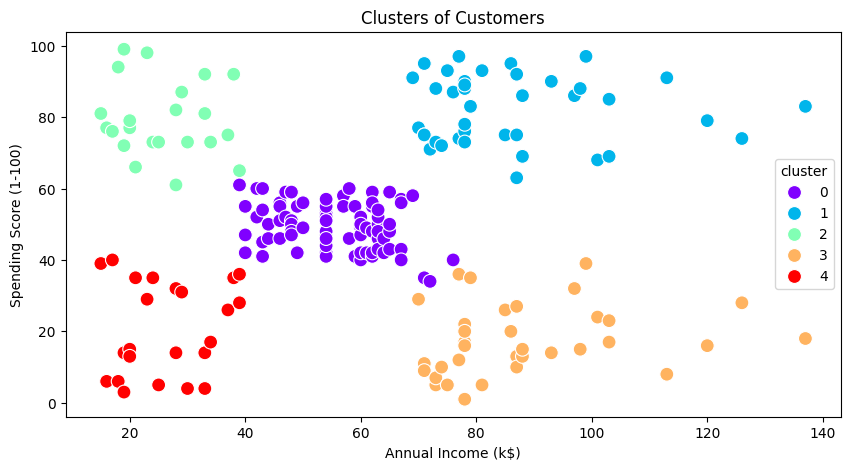

In [ ]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='cluster', palette='rainbow', s=100)
plt.title('Clusters of Customers')
plt.show()

In [ ]:
km_final.cluster_centers_

array([[-0.20091257, -0.02645617],
       [ 0.99158305,  1.23950275],
       [-1.32954532,  1.13217788],
       [ 1.05500302, -1.28443907],
       [-1.30751869, -1.13696536]])

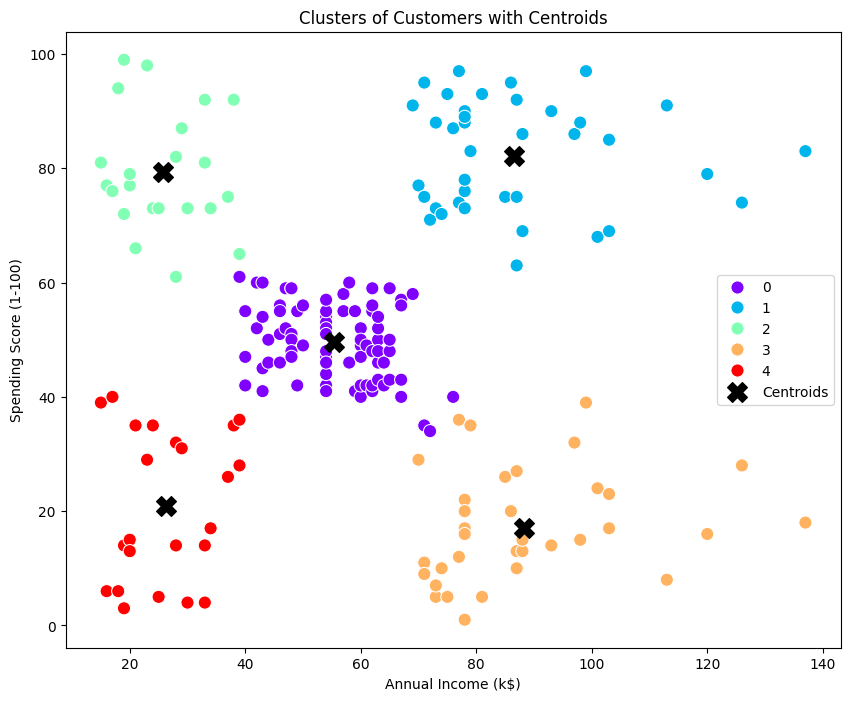

In [ ]:
# Retrieve the scaled centroids from the KMeans model
scaled_centroids = km_final.cluster_centers_

# We inverse transform the entire 2D centroids array to map them back to the original scale
centroids_unscaled = std.inverse_transform(scaled_centroids)

# Create the scatter plot
plt.figure(figsize=(10,8))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='cluster', palette='rainbow', s=90)

# Overlay the centroids
plt.scatter(centroids_unscaled[:, 0], centroids_unscaled[:, 1], color='black', marker='X', s=200, label='Centroids')

plt.title('Clusters of Customers with Centroids')
plt.legend()
plt.show()